# BEVFusion Colab Setup and nuScenes-mini Preprocessing

This notebook prepares a runnable MIT BEVFusion environment on Google Colab and preprocesses nuScenes-mini.

It covers:

1. Runtime and GPU check
2. Google Drive project folders
3. Python 3.8 isolated environment with micromamba
4. PyTorch, OpenMMLab, and BEVFusion dependencies
5. CUDA 11.3 toolkit and GCC 9
6. MIT official BEVFusion clone and CUDA extension build
7. Pretrained checkpoint download
8. nuScenes-mini folder validation
9. nuScenes info pkl generation and filename normalization

Before running: set `Runtime -> Change runtime type -> GPU`, then run cells from top to bottom. Do not use `Run all` on the first attempt.




1.   Colab GPU / runtime 檢查
2.   Google Drive 專案資料夾建立
3.   Python 3.8 micromamba 隔離環境
4.   PyTorch 1.10.1+CUDA 11.3+ OpenMMLab 安裝
5.   CUDA 11.3 toolkit / GCC 9 安裝
MIT 官方
6.   BEVFusion clone 與編譯
7.   core ops smoke test
8.   pretrained checkpoints 下載
9.   nuScenes-mini 結構檢查
10.   info pkl 產生與檔名整理





## 0. Paths

This notebook uses these paths:

- Code: `/content/bevfusion_mit`
- Python env: `/content/bevfusion_env`
- Drive project: `/content/drive/MyDrive/BEVFusion_Project`
- nuScenes-mini root: `/content/drive/MyDrive/BEVFusion_Project/data/nuscenes`
- Checkpoints: `/content/bevfusion_mit/pretrained`

`/content` is temporary Colab storage. Google Drive files persist across sessions.


In [ ]:
# 1. Runtime and GPU check
import os
import sys
import subprocess

print('Python executable:', sys.executable)
print('Python version:', sys.version)
print('cwd:', os.getcwd())

print('GPU:')
subprocess.run('nvidia-smi', shell=True)

print('NVCC:')
subprocess.run('nvcc --version', shell=True)

print('Torch in current Colab kernel:')
try:
    import torch
    print('torch:', torch.__version__)
    print('torch cuda:', torch.version.cuda)
    print('cuda available:', torch.cuda.is_available())
except Exception as exc:
    print('torch import failed:', repr(exc))


Python executable: /usr/bin/python3
Python version: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
cwd: /content
GPU:
NVCC:
Torch in current Colab kernel:
torch: 2.10.0+cu128
torch cuda: 12.8
cuda available: True


In [ ]:
# 2. Mount Google Drive and create project folders
from google.colab import drive
import os

drive.mount('/content/drive')

PROJECT_DRIVE = '/content/drive/MyDrive/BEVFusion_Project'
NUSCENES_ROOT = f'{PROJECT_DRIVE}/data/nuscenes'
OUTPUT_ROOT = f'{PROJECT_DRIVE}/outputs'

for d in [PROJECT_DRIVE, NUSCENES_ROOT, OUTPUT_ROOT]:
    os.makedirs(d, exist_ok=True)

print('PROJECT_DRIVE =', PROJECT_DRIVE)
print('NUSCENES_ROOT =', NUSCENES_ROOT)
print('OUTPUT_ROOT =', OUTPUT_ROOT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DRIVE = /content/drive/MyDrive/BEVFusion_Project
NUSCENES_ROOT = /content/drive/MyDrive/BEVFusion_Project/data/nuscenes
OUTPUT_ROOT = /content/drive/MyDrive/BEVFusion_Project/outputs


## 1. Create Python 3.8 Environment

Do not modify Colab system Python. BEVFusion needs older Python and PyTorch versions, so this notebook creates an isolated micromamba environment at `/content/bevfusion_env`.


In [ ]:
# 3. Install micromamba and create Python 3.8 env
%cd /content

!rm -rf /content/bin /content/bevfusion_env /content/micromamba.tar.bz2
!wget -qO /content/micromamba.tar.bz2 https://micro.mamba.pm/api/micromamba/linux-64/latest
!tar -xjf /content/micromamba.tar.bz2 -C /content

!/content/bin/micromamba create -y -p /content/bevfusion_env python=3.8 pip -c conda-forge
!/content/bin/micromamba run -p /content/bevfusion_env python -m pip install -U pip wheel
!/content/bin/micromamba run -p /content/bevfusion_env python -m pip install setuptools==59.5.0 ninja Cython packaging

!/content/bin/micromamba run -p /content/bevfusion_env python --version


/content
[+] 0.0s
Fetch Shard Index for conda-forge/linux-64                                                ✔ Done (0.1 sec)
Fetch Shard Index for conda-forge/noarch                                                  ✔ Done (0.1 sec)
Fetching and Parsing Packages' Shards                                                     ✔ Done (1.6 sec)
Using Cached Shard Index for conda-forge/linux-64                                                   ✔ Done
Using Cached Shard Index for conda-forge/noarch                                                     ✔ Done
Fetching and Parsing Packages' Shards                                                     ✔ Done (0.1 sec)

Resolving Environment                                                                     ✔ Done (0.6 sec)

Transaction

  Prefix: /content/bevfusion_env

  Updating specs:

   - python=3.8
   - pip


  Package               Version  Build                 Channel          Size
─────────────────────────────────────────────────────────────

In [ ]:
# 4. Install PyTorch 1.10.1 + CUDA 11.3 and OpenMMLab dependencies
!/content/bin/micromamba run -p /content/bevfusion_env python -m pip install   torch==1.10.1+cu113 torchvision==0.11.2+cu113 torchaudio==0.10.1+cu113   -f https://download.pytorch.org/whl/cu113/torch_stable.html

!/content/bin/micromamba run -p /content/bevfusion_env python -m pip install   mmcv-full==1.4.0   -f https://download.openmmlab.com/mmcv/dist/cu113/torch1.10.0/index.html

!/content/bin/micromamba run -p /content/bevfusion_env python -m pip install   mmdet==2.24.0 mmsegmentation==0.24.0

!/content/bin/micromamba run -p /content/bevfusion_env python -m pip install   numpy==1.23.5 numba==0.56.4 nuscenes-devkit==1.1.9   pyquaternion shapely tqdm scikit-image opencv-python-headless matplotlib pandas pyyaml tensorboard torchpack


Looking in links: https://download.pytorch.org/whl/cu113/torch_stable.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 GB 20.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 76.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 98.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 137.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 158.9 MB/s eta 0:00:00
Looking in links: https://download.openmmlab.com/mmcv/dist/cu113/torch1.10.0/index.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 MB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.9/72.9 MB 116.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 806.0/806.0 kB 42.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 74.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.5/803.5 kB 42.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
# 5. Verify isolated environment packages
!/content/bin/micromamba run -p /content/bevfusion_env python -c "import sys, torch, mmcv, mmdet, mmseg, numpy; print('Python:', sys.version); print('Torch:', torch.__version__, 'CUDA:', torch.version.cuda, 'available:', torch.cuda.is_available()); print('mmcv:', mmcv.__version__); print('mmdet:', mmdet.__version__); print('mmseg:', mmseg.__version__); print('numpy:', numpy.__version__)"


Python: 3.8.20 | packaged by conda-forge | (default, Sep 30 2024, 17:52:49) 
[GCC 13.3.0]
Torch: 1.10.1+cu113 CUDA: 11.3 available: True
mmcv: 1.4.0
mmdet: 2.24.0
mmseg: 0.24.0
numpy: 1.23.5


## 2. Install CUDA 11.3 Toolkit and GCC 9

Colab often ships with CUDA 12.x, but the selected PyTorch wheel is built for CUDA 11.3. BEVFusion CUDA extensions should be compiled with CUDA 11.3 `nvcc`. CUDA 11.3 is more stable with GCC 9.


In [ ]:
# 6. Add NVIDIA CUDA 11.3 repo and install cuda-toolkit-11-3
%cd /content

!sudo rm -f /etc/apt/sources.list.d/archive_uri-https_developer_download_nvidia_com_compute_cuda_repos_ubuntu2004_x86_64_-jammy.list
!wget -q https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2004/x86_64/cuda-keyring_1.1-1_all.deb
!sudo dpkg -i cuda-keyring_1.1-1_all.deb
!sudo apt-get update -y
!sudo apt-get install cuda-toolkit-11-3 -y

!/usr/local/cuda-11.3/bin/nvcc --version


/content
(Reading database ... 122363 files and directories currently installed.)
Preparing to unpack cuda-keyring_1.1-1_all.deb ...
Unpacking cuda-keyring (1.1-1) over (1.1-1) ...
Setting up cuda-keyring (1.1-1) ...
Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2004/x86_64  InRelease [1,581 B]
Get:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Get:5 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ Packages [95.6 kB]
Get:6 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:7 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2004/x86_64  Packages [2,821 kB]
Get:8 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2,646 kB]
Get:9 http://security.ubuntu.com/ubuntu jammy-security/restricted a

In [ ]:
# 7. Install GCC/G++ 9
!sudo apt-get install gcc-9 g++-9 -y
!gcc-9 --version
!g++-9 --version

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  cpp-9 gcc-9-base libasan5 libgcc-9-dev libstdc++-9-dev
Suggested packages:
  gcc-9-locales g++-9-multilib gcc-9-doc gcc-9-multilib libstdc++-9-doc
The following NEW packages will be installed:
  cpp-9 g++-9 gcc-9 gcc-9-base libasan5 libgcc-9-dev libstdc++-9-dev
0 upgraded, 7 newly installed, 0 to remove and 71 not upgraded.
Need to get 41.4 MB of archives.
After this operation, 138 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy-updates/universe amd64 gcc-9-base amd64 9.5.0-1ubuntu1~22.04.1 [204 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy-updates/universe amd64 cpp-9 amd64 9.5.0-1ubuntu1~22.04.1 [10.6 MB]
Get:3 http://archive.ubuntu.com/ubuntu jammy-updates/universe amd64 libasan5 amd64 9.5.0-1ubuntu1~22.04.1 [3,141 kB]
Get:4 http://archive.ubuntu.com/ubuntu jammy-updates/universe amd64 libgcc

## 3. Clone and Build MIT Official BEVFusion

Official repo: `https://github.com/mit-han-lab/bevfusion.git`

This notebook uses the MIT official BEVFusion repo directly instead of RoboBEV's embedded `zoo/BEVFusion`, because the embedded copy can miss CUDA source files or headers in Colab workflows.


In [ ]:
# 8. Clone MIT official BEVFusion
%cd /content

!rm -rf /content/bevfusion_mit
!git clone https://github.com/mit-han-lab/bevfusion.git /content/bevfusion_mit

%cd /content/bevfusion_mit
!git submodule update --init --recursive

!pwd
!find . -maxdepth 2 -type f \( -name 'README*' -o -name 'setup.py' -o -name 'requirements*.txt' \) -print


/content
Cloning into '/content/bevfusion_mit'...
remote: Enumerating objects: 638, done.
remote: Counting objects: 100% (475/475), done.
remote: Compressing objects: 100% (326/326), done.
remote: Total 638 (delta 217), reused 149 (delta 149), pack-reused 163 (from 1)
Receiving objects: 100% (638/638), 8.96 MiB | 21.53 MiB/s, done.
Resolving deltas: 100% (227/227), done.
/content/bevfusion_mit
/content/bevfusion_mit
./README.md
./setup.py


In [ ]:
# 9. Build BEVFusion CUDA extensions
%cd /content/bevfusion_mit

!rm -rf build mmdet3d.egg-info

!CC=/usr/bin/gcc-9  CXX=/usr/bin/g++-9  CUDAHOSTCXX=/usr/bin/g++-9  CUDA_HOME=/usr/local/cuda-11.3  PATH=/usr/local/cuda-11.3/bin:$PATH  LD_LIBRARY_PATH=/usr/local/cuda-11.3/lib64:$LD_LIBRARY_PATH  MAX_JOBS=2  TORCH_CUDA_ARCH_LIST=7.5  NVCC_APPEND_FLAGS="-allow-unsupported-compiler"  /content/bin/micromamba run -p /content/bevfusion_env python setup.py develop


/content/bevfusion_mit
running develop
/content/bevfusion_env/lib/python3.8/site-packages/setuptools/command/easy_install.py:156: EasyInstallDeprecationWarning: easy_install command is deprecated. Use build and pip and other standards-based tools.
  warnings.warn(
/content/bevfusion_env/lib/python3.8/site-packages/setuptools/command/install.py:34: SetuptoolsDeprecationWarning: setup.py install is deprecated. Use build and pip and other standards-based tools.
  warnings.warn(
running egg_info
creating mmdet3d.egg-info
writing mmdet3d.egg-info/PKG-INFO
writing dependency_links to mmdet3d.egg-info/dependency_links.txt
writing top-level names to mmdet3d.egg-info/top_level.txt
writing manifest file 'mmdet3d.egg-info/SOURCES.txt'
reading manifest file 'mmdet3d.egg-info/SOURCES.txt'
adding license file 'LICENSE'
writing manifest file 'mmdet3d.egg-info/SOURCES.txt'
running build_ext
building 'mmdet3d.ops.spconv.sparse_conv_ext' extension
creating /content/bevfusion_mit/build
creating /content/

In [ ]:
# 10. Disable optional feature_decorator import for the Colab baseline build
# feature_decorator_ext is not always built by setup.py. The detection baseline usually does not need it.
%cd /content/bevfusion_mit

!cp -n mmdet3d/ops/__init__.py mmdet3d/ops/__init__.py.bak
!python -c "p='mmdet3d/ops/__init__.py'; s=open(p).read(); s=s.replace('from .feature_decorator import feature_decorator', '# from .feature_decorator import feature_decorator  # optional, disabled for Colab baseline'); open(p,'w').write(s)"
!grep -n 'feature_decorator' mmdet3d/ops/__init__.py


/content/bevfusion_mit
12:# from .feature_decorator import feature_decorator  # optional, disabled for Colab baseline
93:    "feature_decorator",


In [ ]:
# 11. Smoke test: verify core CUDA ops import
%cd /content/bevfusion_mit

!/content/bin/micromamba run -p /content/bevfusion_env python -c "import torch; print('torch', torch.__version__, torch.cuda.is_available()); import mmdet3d; print('mmdet3d', mmdet3d.__file__); import mmdet3d.ops.spconv.sparse_conv_ext; import mmdet3d.ops.bev_pool.bev_pool_ext; import mmdet3d.ops.iou3d.iou3d_cuda; import mmdet3d.ops.voxel.voxel_layer; print('core compiled ops import OK')"


/content/bevfusion_mit
torch 1.10.1+cu113 True
mmdet3d /content/bevfusion_mit/mmdet3d/__init__.py
core compiled ops import OK


## 4. Download Pretrained Checkpoints

The detection baseline uses `pretrained/bevfusion-det.pth`.


In [ ]:
# 12. Download pretrained checkpoints
%cd /content/bevfusion_mit

!bash tools/download_pretrained.sh

print('checkpoints:')
!find pretrained -maxdepth 2 -type f -print | sort


/content/bevfusion_mit
--2026-05-26 10:44:10--  https://www.dropbox.com/scl/fi/ulaz9z4wdwtypjhx7xdi3/bevfusion-det.pth?rlkey=ovusfi2rchjub5oafogou255v
Resolving www.dropbox.com (www.dropbox.com)... 162.125.80.18, 2620:100:6035:18::a27d:5512
Connecting to www.dropbox.com (www.dropbox.com)|162.125.80.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uce6e035eb9efd017cd4d0071cdb.dl.dropboxusercontent.com/cd/0/inline/DBP_H4SrsNXPsXpFEfkKGlR2jG8DuZ1VibXjuIGi_kLniCiz3FALSfOTTy9kCngFjmGVwHr4oolHyJNZRq01j5dKmTMEbvyJSlLrbgnk3PBQhmt5IfoNoxibR-VDnVUzKhrRcau5331z_RbL7yYNI1-6/file# [following]
--2026-05-26 10:44:11--  https://uce6e035eb9efd017cd4d0071cdb.dl.dropboxusercontent.com/cd/0/inline/DBP_H4SrsNXPsXpFEfkKGlR2jG8DuZ1VibXjuIGi_kLniCiz3FALSfOTTy9kCngFjmGVwHr4oolHyJNZRq01j5dKmTMEbvyJSlLrbgnk3PBQhmt5IfoNoxibR-VDnVUzKhrRcau5331z_RbL7yYNI1-6/file
Resolving uce6e035eb9efd017cd4d0071cdb.dl.dropboxusercontent.com (uce6e035eb9efd017cd4d0071cdb.dl.dropboxuserconte

## 5. Validate nuScenes-mini Folder Structure

Download nuScenes mini from the official nuScenes website and extract it to:

`/content/drive/MyDrive/BEVFusion_Project/data/nuscenes`

The folder should contain:

- `samples/`
- `sweeps/`
- `maps/`
- `v1.0-mini/`


In [ ]:
# 13. Inspect nuScenes-mini structure
print('NUSCENES_ROOT =', NUSCENES_ROOT)
!find {NUSCENES_ROOT} -maxdepth 2 -type d | sort | head -80
!find {NUSCENES_ROOT} -maxdepth 2 -type f | sort | head -80


NUSCENES_ROOT = /content/drive/MyDrive/BEVFusion_Project/data/nuscenes
/content/drive/MyDrive/BEVFusion_Project/data/nuscenes
/content/drive/MyDrive/BEVFusion_Project/data/nuscenes/maps
/content/drive/MyDrive/BEVFusion_Project/data/nuscenes/nuscenes_gt_database
/content/drive/MyDrive/BEVFusion_Project/data/nuscenes/samples
/content/drive/MyDrive/BEVFusion_Project/data/nuscenes/samples/CAM_BACK
/content/drive/MyDrive/BEVFusion_Project/data/nuscenes/samples/CAM_BACK_LEFT
/content/drive/MyDrive/BEVFusion_Project/data/nuscenes/samples/CAM_BACK_RIGHT
/content/drive/MyDrive/BEVFusion_Project/data/nuscenes/samples/CAM_FRONT
/content/drive/MyDrive/BEVFusion_Project/data/nuscenes/samples/CAM_FRONT_LEFT
/content/drive/MyDrive/BEVFusion_Project/data/nuscenes/samples/CAM_FRONT_RIGHT
/content/drive/MyDrive/BEVFusion_Project/data/nuscenes/samples/LIDAR_TOP
/content/drive/MyDrive/BEVFusion_Project/data/nuscenes/samples/RADAR_BACK_LEFT
/content/drive/MyDrive/BEVFusion_Project/data/nuscenes/samples/RAD

In [ ]:
# 14. Validate required nuScenes-mini folders
import os
required = ['samples', 'sweeps', 'maps', 'v1.0-mini']
missing = [x for x in required if not os.path.exists(os.path.join(NUSCENES_ROOT, x))]
if missing:
    raise RuntimeError('Missing nuScenes-mini folders: ' + ', '.join(missing))
print('nuScenes-mini folder structure OK')


nuScenes-mini folder structure OK


## 6. Generate nuScenes Info PKL Files

MIT BEVFusion `tools/create_data.py` may create info pkl files successfully and then fail later during GT database creation because mini-mode filenames do not always match the expected GT database filename. This notebook allows that command to exit non-zero, then normalizes the info pkl filenames.

For baseline evaluation, the key files are:

- `nuscenes_infos_train.pkl`
- `nuscenes_infos_val.pkl`


In [ ]:
# 15. Run create_data.py to generate info pkl files
# This may fail during GT database creation. Continue if info pkl files were generated.
%cd /content/bevfusion_mit

!rm -rf /content/bevfusion_mit/nuscenes
!mkdir -p /content/bevfusion_mit/nuscenes

!set +e; /content/bin/micromamba run -p /content/bevfusion_env python tools/create_data.py nuscenes   --root-path {NUSCENES_ROOT}   --out-dir {NUSCENES_ROOT}   --extra-tag nuscenes   --version v1.0-mini   --max-sweeps 10; echo $? > /content/create_data_exit_code.txt

print('create_data exit code:')
!cat /content/create_data_exit_code.txt

print('Generated pkl candidates:')
!find /content/bevfusion_mit -maxdepth 3 -type f -name '*infos*.pkl' -print | sort
!find {NUSCENES_ROOT} -maxdepth 1 -type f -name '*infos*.pkl' -print | sort


/content/bevfusion_mit
Loading NuScenes tables for version v1.0-mini...
23 category,
8 attribute,
4 visibility,
911 instance,
12 sensor,
120 calibrated_sensor,
31206 ego_pose,
8 log,
10 scene,
404 sample,
31206 sample_data,
18538 sample_annotation,
4 map,
Done loading in 12.394 seconds.
Reverse indexing ...
Done reverse indexing in 0.1 seconds.
total scene num: 10
exist scene num: 10
train scene: 8, val scene: 2
[>>] 404/404, 1.7 task/s, elapsed: 237s, ETA:     0s
nuscenes
train sample: 323, val sample: 81
Create GT Database of NuScenesDataset
[>>] 323/323, 0.0 task/s, elapsed: 13823s, ETA:     0s
load 3068 pedestrian database infos
load 4082 car database infos
load 773 traffic_cone database infos
load 147 bicycle database infos
load 1851 barrier database infos
load 451 truck database infos
load 337 bus database infos
load 174 construction_vehicle database infos
load 57 movable_object.pushable_pullable database infos
load 179 motorcycle database infos
load 13 movable_object.debris data

In [ ]:
# 16. Normalize info pkl filenames into the nuScenes root
import shutil
from pathlib import Path

root = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes")

pairs = [
    (root / "nuscenes_infos_train_radar.pkl", root / "nuscenes_infos_train.pkl"),
    (root / "nuscenes_infos_val_radar.pkl", root / "nuscenes_infos_val.pkl"),
]

for src, dst in pairs:
    if not src.exists():
        print("missing:", src)
        continue

    if src.resolve() == dst.resolve():
        print("skip same file:", src)
        continue

    shutil.copy2(src, dst)
    print("copied:", src.name, "->", dst.name, dst.stat().st_size)

copied: nuscenes_infos_train_radar.pkl -> nuscenes_infos_train.pkl 16301204
copied: nuscenes_infos_val_radar.pkl -> nuscenes_infos_val.pkl 4285942


In [ ]:
# 17. Optional: create GT database for training
# Usually not required for evaluation-only baseline.
RUN_GT_DATABASE = False

if RUN_GT_DATABASE:
    %cd /content/bevfusion_mit
    !/content/bin/micromamba run -p /content/bevfusion_env python -c "from tools.data_converter.create_gt_database import create_groundtruth_database; create_groundtruth_database('NuScenesDataset', '{NUSCENES_ROOT}', 'nuscenes', '{NUSCENES_ROOT}/nuscenes_infos_train.pkl')"
else:
    print('Skipped GT database. Set RUN_GT_DATABASE = True if you need training database.')


Skipped GT database. Set RUN_GT_DATABASE = True if you need training database.


In [ ]:
# 18. Final setup check
print('Info files:')
!ls -lh {NUSCENES_ROOT}/*infos*.pkl

print('Checkpoints:')
!ls -lh /content/bevfusion_mit/pretrained/*.pth

print('Recommended baseline config:')
print('/content/bevfusion_mit/configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml')
print('/content/bevfusion_mit/pretrained/bevfusion-det.pth')


Info files:
-rw------- 1 root root 2.7M May 26 14:41 /content/drive/MyDrive/BEVFusion_Project/data/nuscenes/nuscenes_dbinfos_train.pkl
-rw------- 1 root root  16M May 17 16:49 /content/drive/MyDrive/BEVFusion_Project/data/nuscenes/nuscenes_infos_train.pkl
-rw------- 1 root root  16M May 17 16:49 /content/drive/MyDrive/BEVFusion_Project/data/nuscenes/nuscenes_infos_train_radar.pkl
-rw------- 1 root root 4.1M May 21 04:42 /content/drive/MyDrive/BEVFusion_Project/data/nuscenes/nuscenes_infos_val.pkl
-rw------- 1 root root 4.1M May 21 04:42 /content/drive/MyDrive/BEVFusion_Project/data/nuscenes/nuscenes_infos_val_radar.pkl
Checkpoints:
-rw-r--r-- 1 root root 157M May 26 10:44 /content/bevfusion_mit/pretrained/bevfusion-det.pth
-rw-r--r-- 1 root root 165M May 26 10:44 /content/bevfusion_mit/pretrained/bevfusion-seg.pth
-rw-r--r-- 1 root root 170M May 26 10:44 /content/bevfusion_mit/pretrained/camera-only-det.pth
-rw-r--r-- 1 root root 192M May 26 10:45 /content/bevfusion_mit/pretrained/came

## 7. Done

If all previous cells succeed, this Colab runtime has:

- MIT BEVFusion compiled
- Core CUDA ops import verified
- Pretrained detection checkpoint downloaded
- nuScenes-mini info pkl files generated

Recommended baseline inputs:

- Config: `configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml`
- Checkpoint: `pretrained/bevfusion-det.pth`
- Data root: `/content/drive/MyDrive/BEVFusion_Project/data/nuscenes`

If you restart Colab, `/content` is erased and the environment must be rebuilt. Google Drive files persist.


**clean nuScenes-mini baseline**

1. 連結資料集到 BEVFusion 預期位置

In [ ]:
%cd /content/bevfusion_mit

!mkdir -p data
!rm -rf data/nuscenes
!ln -s /content/drive/MyDrive/BEVFusion_Project/data/nuscenes data/nuscenes

!ls -lh data
!ls -lh data/nuscenes/*infos*.pkl

/content/bevfusion_mit
total 0
lrwxrwxrwx 1 root root 54 May 26 14:41 nuscenes -> /content/drive/MyDrive/BEVFusion_Project/data/nuscenes
-rw------- 1 root root 2.7M May 26 14:41 data/nuscenes/nuscenes_dbinfos_train.pkl
-rw------- 1 root root  16M May 17 16:49 data/nuscenes/nuscenes_infos_train.pkl
-rw------- 1 root root  16M May 17 16:49 data/nuscenes/nuscenes_infos_train_radar.pkl
-rw------- 1 root root 4.1M May 21 04:42 data/nuscenes/nuscenes_infos_val.pkl
-rw------- 1 root root 4.1M May 21 04:42 data/nuscenes/nuscenes_infos_val_radar.pkl


2. 先確認 config / checkpoint 存在

In [ ]:
%cd /content/bevfusion_mit

CONFIG="configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml"
CKPT="pretrained/bevfusion-det.pth"

!test -f $CONFIG && echo "CONFIG OK: $CONFIG"
!test -f $CKPT && echo "CHECKPOINT OK: $CKPT"

/content/bevfusion_mit
CONFIG OK: configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml
CHECKPOINT OK: pretrained/bevfusion-det.pth


3. 跑 clean baseline evaluation

In [ ]:
%cd /content/bevfusion_mit

# backup
!cp -n mmdet3d/models/backbones/__init__.py mmdet3d/models/backbones/__init__.py.bak

# disable radar encoder import
!python -c "p='mmdet3d/models/backbones/__init__.py'; s=open(p).read(); s=s.replace('from .radar_encoder import *', '# from .radar_encoder import *  # disabled for camera+lidar baseline'); open(p,'w').write(s)"

!grep -n "radar_encoder" mmdet3d/models/backbones/__init__.py

/content/bevfusion_mit
9:# from .radar_encoder import *  # disabled for camera+lidar baseline


## 安裝 OpenMPI + mpi4py

In [ ]:
!sudo apt-get update -y
!sudo apt-get install -y openmpi-bin libopenmpi-dev

!/content/bin/micromamba run -p /content/bevfusion_env python -m pip install mpi4py==3.0.3

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2004/x86_64  InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:4 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:5 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:6 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:7 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Get:8 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]
Get:9 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:10 https://r2u.stat.illinois.edu/ubuntu jammy/main all Packages [10.2 MB]
Hit:11 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:12 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:13 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Get:14 https://

In [ ]:
!/content/bin/micromamba run -p /content/bevfusion_env python -c "from mpi4py import MPI; print('mpi4py OK', MPI.COMM_WORLD.Get_rank(), MPI.COMM_WORLD.Get_size())"

mpi4py OK 0 1


In [ ]:
%cd /content/bevfusion_mit

!python - <<'PY'
from pathlib import Path

p = Path("mmdet3d/models/vtransforms/depth_lss.py")
s = p.read_text()

if "add_depth_features=False" not in s:
    old = "dbound=dbound,\n        )"
    new = "dbound=dbound,\n            add_depth_features=False,\n        )"
    if old not in s:
        raise RuntimeError("patch target not found; please show depth_lss.py super().__init__ block")
    s = s.replace(old, new, 1)
    p.write_text(s)

print("patched depth_lss.py: add_depth_features=False")

/content/bevfusion_mit
/bin/bash: line 1: warning: here-document at line 1 delimited by end-of-file (wanted `PY')
patched depth_lss.py: add_depth_features=False


In [ ]:
%cd /content/bevfusion_mit

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/baseline_clean_mini

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml \
  pretrained/bevfusion-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/baseline_clean_mini/eval.log

/content/bevfusion_mit
Config (path: configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 6, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 6}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': -1, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-54.0, -54.0, -5.0, 54.0, 54.0, 3.0], 'voxel_size': [0.075, 0.075, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.9, 1.1], 'rotate': [-0.78539816, 0.785398

## 把 baseline 結果整理成一個固定紀錄檔

In [ ]:
BASELINE_TXT = "/content/drive/MyDrive/BEVFusion_Project/outputs/baseline_clean_mini/baseline_metrics.txt"

baseline = """Clean nuScenes-mini baseline
Model: MIT BEVFusion camera+lidar convfuser
Config: configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml
Checkpoint: pretrained/bevfusion-det.pth
Dataset: nuScenes-mini clean

mAP: 0.5746
NDS: 0.5803
mATE: 0.4057
mASE: 0.4454
mAOE: 0.4678
mAVE: 0.4319
mAAE: 0.3194
"""

with open(BASELINE_TXT, "w") as f:
    f.write(baseline)

print("Saved:", BASELINE_TXT)

## 建立實驗資料夾

In [ ]:
PROJECT_ROOT = "/content/drive/MyDrive/BEVFusion_Project"
NUSC_ROOT = f"{PROJECT_ROOT}/data/nuscenes"

EXP_ROOT = f"{PROJECT_ROOT}/outputs/robustness"
CLEAN_OUT = f"{PROJECT_ROOT}/outputs/baseline_clean_mini"
GAUSS_S1_OUT = f"{EXP_ROOT}/gaussian_noise_s1"

!mkdir -p {EXP_ROOT}
!mkdir -p {GAUSS_S1_OUT}

print("Baseline:", CLEAN_OUT)
print("First robustness experiment:", GAUSS_S1_OUT)

## 建立 corrupted dataset 的資料夾骨架

In [ ]:
from pathlib import Path
import shutil
import os

SRC = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes")
DST = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes_gaussian_s1")

print("SRC exists:", SRC.exists())
print("SRC:", SRC)

if DST.exists():
    shutil.rmtree(DST)

DST.mkdir(parents=True, exist_ok=True)

for name in ["v1.0-mini", "maps", "samples", "sweeps"]:
    src_path = SRC / name
    dst_path = DST / name
    print("copy", src_path, "->", dst_path)
    shutil.copytree(src_path, dst_path)

for p in SRC.glob("*.pkl"):
    print("copy", p.name)
    shutil.copy2(p, DST / p.name)

license_path = SRC / "LICENSE"
if license_path.exists():
    shutil.copy2(license_path, DST / "LICENSE")

print("Created:", DST)

## Gaussian noise severity 1
* corruption: Gaussian noise
* severity: 1
* target: camera images only
* dataset: nuScenes-mini
* model: BEVFusion camera+lidar

## 對所有 camera images 加 Gaussian noise severity 1

## 檢查 camera 圖片數量

In [ ]:
from pathlib import Path

DST = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes_gaussian_s1")

camera_dirs = {
    "CAM_FRONT",
    "CAM_FRONT_RIGHT",
    "CAM_FRONT_LEFT",
    "CAM_BACK",
    "CAM_BACK_RIGHT",
    "CAM_BACK_LEFT",
}

image_paths = []
for root_name in ["samples", "sweeps"]:
    root = DST / root_name
    for p in root.rglob("*"):
        if p.parent.name in camera_dirs and p.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            image_paths.append(p)

print("camera images:", len(image_paths))
print("first image:", image_paths[0] if image_paths else None)

camera images: 14024
first image: /content/drive/MyDrive/BEVFusion_Project/data/nuscenes_gaussian_s1/samples/CAM_BACK_RIGHT/n008-2018-08-01-15-16-36-0400__CAM_BACK_RIGHT__1533151604528113.jpg


In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
from tqdm import tqdm

SRC = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes")
DST = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes_gaussian_s1")
DONE = DST / "_gaussian_noise_s1_done.txt"

camera_dirs = {
    "CAM_FRONT",
    "CAM_FRONT_RIGHT",
    "CAM_FRONT_LEFT",
    "CAM_BACK",
    "CAM_BACK_RIGHT",
    "CAM_BACK_LEFT",
}


# Severity 1: light Gaussian noise
sigma = 0.08 * 255.0

image_paths = []
for root_name in ["samples", "sweeps"]:
    root = DST / root_name
    for p in root.rglob("*"):
        if p.parent.name in camera_dirs and p.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            image_paths.append(p)

done_set = set()
if DONE.exists():
    done_set = set(DONE.read_text().splitlines())

pending = [p for p in image_paths if str(p) not in done_set]

print("total camera images:", len(image_paths))
print("already done:", len(done_set))
print("pending:", len(pending))

rng = np.random.default_rng(0)

with DONE.open("a") as f:
    for p in tqdm(pending):
        img = Image.open(p).convert("RGB")
        arr = np.asarray(img).astype(np.float32)

        noise = rng.normal(0.0, sigma, arr.shape)
        noisy = np.clip(arr + noise, 0, 255).astype(np.uint8)

        Image.fromarray(noisy).save(p, quality=95)
        f.write(str(p) + "\n")
        f.flush()

print("Gaussian noise severity 1 complete or resumable:", DST)

total camera images: 14024
already done: 14024
pending: 0


0it [00:00, ?it/s]

Gaussian noise severity 1 complete or resumable: /content/drive/MyDrive/BEVFusion_Project/data/nuscenes_gaussian_s1


In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!ln -s /content/drive/MyDrive/BEVFusion_Project/data/nuscenes_gaussian_s1 data/nuscenes

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/gaussian_noise_s1

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml \
  pretrained/bevfusion-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/gaussian_noise_s1/eval.log

/content/bevfusion_mit
Config (path: configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 6, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 6}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': -1, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-54.0, -54.0, -5.0, 54.0, 54.0, 3.0], 'voxel_size': [0.075, 0.075, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.9, 1.1], 'rotate': [-0.78539816, 0.785398

## 建立 s3 本機資料集

In [ ]:
from pathlib import Path
import shutil
import os

SRC = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes")
DST = Path("/content/nuscenes_gaussian_s3")

if DST.exists():
    shutil.rmtree(DST)

DST.mkdir(parents=True, exist_ok=True)

shutil.copytree(SRC / "v1.0-mini", DST / "v1.0-mini")
shutil.copytree(SRC / "maps", DST / "maps")

for p in SRC.glob("*.pkl"):
    shutil.copy2(p, DST / p.name)

if (SRC / "LICENSE").exists():
    shutil.copy2(SRC / "LICENSE", DST / "LICENSE")

(DST / "samples").mkdir()

camera_dirs = [
    "CAM_FRONT",
    "CAM_FRONT_RIGHT",
    "CAM_FRONT_LEFT",
    "CAM_BACK",
    "CAM_BACK_RIGHT",
    "CAM_BACK_LEFT",
]

for cam in camera_dirs:
    shutil.copytree(SRC / "samples" / cam, DST / "samples" / cam)

os.symlink(SRC / "samples" / "LIDAR_TOP", DST / "samples" / "LIDAR_TOP")
os.symlink(SRC / "sweeps", DST / "sweeps")

print("Created local corrupted dataset:", DST)

Created local corrupted dataset: /content/nuscenes_gaussian_s3


## 加 Gaussian noise severity 3

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
from tqdm import tqdm

DST = Path("/content/nuscenes_gaussian_s3")

camera_dirs = {
    "CAM_FRONT",
    "CAM_FRONT_RIGHT",
    "CAM_FRONT_LEFT",
    "CAM_BACK",
    "CAM_BACK_RIGHT",
    "CAM_BACK_LEFT",
}

image_paths = []
for cam in camera_dirs:
    image_paths.extend((DST / "samples" / cam).glob("*.jpg"))
    image_paths.extend((DST / "samples" / cam).glob("*.jpeg"))
    image_paths.extend((DST / "samples" / cam).glob("*.png"))

print("camera sample images:", len(image_paths))

# Severity 3
sigma = 0.18 * 255.0
rng = np.random.default_rng(0)

for p in tqdm(image_paths):
    img = Image.open(p).convert("RGB")
    arr = np.asarray(img).astype(np.float32)
    noise = rng.normal(0.0, sigma, arr.shape)
    noisy = np.clip(arr + noise, 0, 255).astype(np.uint8)
    Image.fromarray(noisy).save(p, quality=95)

print("Gaussian noise severity 3 done")

camera sample images: 2424


100%|██████████| 2424/2424 [05:35<00:00,  7.22it/s]

Gaussian noise severity 3 done


## 跑 evaluation

In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_gaussian_s3 data/nuscenes

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/gaussian_noise_s3

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml \
  pretrained/bevfusion-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/gaussian_noise_s3/eval.log

/content/bevfusion_mit
Config (path: configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 6, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 6}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': -1, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-54.0, -54.0, -5.0, 54.0, 54.0, 3.0], 'voxel_size': [0.075, 0.075, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.9, 1.1], 'rotate': [-0.78539816, 0.785398

## 建立 s5 本機資料集

In [ ]:
from pathlib import Path
import shutil
import os

SRC = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes")
DST = Path("/content/nuscenes_gaussian_s5")

if DST.exists():
    shutil.rmtree(DST)

DST.mkdir(parents=True, exist_ok=True)

shutil.copytree(SRC / "v1.0-mini", DST / "v1.0-mini")
shutil.copytree(SRC / "maps", DST / "maps")

for p in SRC.glob("*.pkl"):
    shutil.copy2(p, DST / p.name)

if (SRC / "LICENSE").exists():
    shutil.copy2(SRC / "LICENSE", DST / "LICENSE")

(DST / "samples").mkdir()

camera_dirs = [
    "CAM_FRONT",
    "CAM_FRONT_RIGHT",
    "CAM_FRONT_LEFT",
    "CAM_BACK",
    "CAM_BACK_RIGHT",
    "CAM_BACK_LEFT",
]

for cam in camera_dirs:
    shutil.copytree(SRC / "samples" / cam, DST / "samples" / cam)

os.symlink(SRC / "samples" / "LIDAR_TOP", DST / "samples" / "LIDAR_TOP")
os.symlink(SRC / "sweeps", DST / "sweeps")

print("Created local corrupted dataset:", DST)

KeyboardInterrupt: 

## 加 Gaussian noise severity 5

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
from tqdm import tqdm

DST = Path("/content/nuscenes_gaussian_s5")

camera_dirs = {
    "CAM_FRONT",
    "CAM_FRONT_RIGHT",
    "CAM_FRONT_LEFT",
    "CAM_BACK",
    "CAM_BACK_RIGHT",
    "CAM_BACK_LEFT",
}

image_paths = []
for cam in camera_dirs:
    image_paths.extend((DST / "samples" / cam).glob("*.jpg"))
    image_paths.extend((DST / "samples" / cam).glob("*.jpeg"))
    image_paths.extend((DST / "samples" / cam).glob("*.png"))

print("camera sample images:", len(image_paths))

# Severity 5
sigma = 0.38 * 255.0
rng = np.random.default_rng(0)

for p in tqdm(image_paths):
    img = Image.open(p).convert("RGB")
    arr = np.asarray(img).astype(np.float32)
    noise = rng.normal(0.0, sigma, arr.shape)
    noisy = np.clip(arr + noise, 0, 255).astype(np.uint8)
    Image.fromarray(noisy).save(p, quality=95)

print("Gaussian noise severity 5 done")

camera sample images: 2424


100%|██████████| 2424/2424 [05:39<00:00,  7.13it/s]

Gaussian noise severity 5 done


## 跑 evaluation

In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_gaussian_s5 data/nuscenes

!readlink -f data/nuscenes
!find data/nuscenes/samples -path "*CAM_*" -type f | wc -l

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/gaussian_noise_s5

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml \
  pretrained/bevfusion-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/gaussian_noise_s5/eval.log

/content/bevfusion_mit
/content/nuscenes_gaussian_s5
2424
Config (path: configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 6, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 6}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': -1, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-54.0, -54.0, -5.0, 54.0, 54.0, 3.0], 'voxel_size': [0.075, 0.075, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.9, 1.1

## 把 clean 和 Gaussian noise存成一個 CSV

In [ ]:
from pathlib import Path
import math
import pandas as pd

# ====== 每次實驗改這四個 ======
experiment = "gaussian_noise_s5"
corruption = "gaussian_noise"
severity = 5
eval_log = Path("/content/drive/MyDrive/BEVFusion_Project/outputs/robustness/gaussian_noise_s5/eval.log")
# ==============================

out_dir = Path("/content/drive/MyDrive/BEVFusion_Project/outputs/robustness")
summary_csv = out_dir / "robustness_summary.csv"
detail_csv = out_dir / "robustness_detail_metrics.csv"

clean_ref = {
    "mAP": 0.5746,
    "NDS": 0.5803,
    "mATE": 0.4057,
    "mASE": 0.4454,
    "mAOE": 0.4678,
    "mAVE": 0.4319,
    "mAAE": 0.3194,
}

text = eval_log.read_text()

dict_lines = []
for line in text.splitlines():
    line = line.strip()
    if line.startswith("{'object/") and line.endswith("}"):
        dict_lines.append(line)

if not dict_lines:
    raise RuntimeError("找不到 metrics dict，請確認 eval.log 裡有最後那段 {'object/...': ...}")

metrics = eval(dict_lines[-1], {"__builtins__": {}}, {"nan": float("nan")})

def clean_value(v):
    if isinstance(v, float) and math.isnan(v):
        return "nan"
    return v

summary_row = {
    "experiment": experiment,
    "corruption": corruption,
    "severity": severity,
    "mAP": metrics["object/map"],
    "NDS": metrics["object/nds"],
    "mATE": metrics["object/mATE"],
    "mASE": metrics["object/mASE"],
    "mAOE": metrics["object/mAOE"],
    "mAVE": metrics["object/mAVE"],
    "mAAE": metrics["object/mAAE"],
}

summary_row["mAP_drop"] = clean_ref["mAP"] - summary_row["mAP"]
summary_row["NDS_drop"] = clean_ref["NDS"] - summary_row["NDS"]

summary_fields = [
    "experiment", "corruption", "severity",
    "mAP", "NDS", "mATE", "mASE", "mAOE", "mAVE", "mAAE",
    "mAP_drop", "NDS_drop",
]

if summary_csv.exists():
    summary_df = pd.read_csv(summary_csv)
    summary_df = summary_df[summary_df["experiment"] != experiment]
else:
    summary_df = pd.DataFrame(columns=summary_fields)

summary_df = pd.concat([summary_df, pd.DataFrame([summary_row])], ignore_index=True)
summary_df = summary_df[summary_fields]
summary_df.to_csv(summary_csv, index=False)

detail_rows = []
for k, v in metrics.items():
    detail_rows.append({
        "experiment": experiment,
        "corruption": corruption,
        "severity": severity,
        "metric": k,
        "value": clean_value(v),
    })

detail_fields = ["experiment", "corruption", "severity", "metric", "value"]

if detail_csv.exists():
    detail_df = pd.read_csv(detail_csv)
    detail_df = detail_df[detail_df["experiment"] != experiment]
else:
    detail_df = pd.DataFrame(columns=detail_fields)

detail_df = pd.concat([detail_df, pd.DataFrame(detail_rows)], ignore_index=True)
detail_df = detail_df[detail_fields]
detail_df.to_csv(detail_csv, index=False)

print("Saved summary:", summary_csv)
print("Saved detail:", detail_csv)

display(summary_df)

Saved summary: /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/robustness_summary.csv
Saved detail: /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/robustness_detail_metrics.csv


,experiment,corruption,severity,mAP,NDS,mATE,mASE,mAOE,mAVE,mAAE,mAP_drop,NDS_drop
0,clean,none,0,0.574600,0.580300,0.4057,0.4454,0.4678,0.4319,0.3194,0.000000,0.000000
1,gaussian_noise_s1,gaussian_noise,1,0.574678,0.580129,0.4059,0.4455,0.4681,0.4335,0.3191,-0.000078,0.000171
2,gaussian_noise_s3,gaussian_noise,3,0.574531,0.579942,0.4058,0.4456,0.4685,0.4342,0.3192,0.000069,0.000358
3,gaussian_noise_s5,gaussian_noise,5,0.574133,0.579818,0.4055,0.4453,0.4682,0.4342,0.3192,0.000467,0.000482


In [ ]:
from pathlib import Path
from PIL import Image, ImageFilter
from tqdm import tqdm
import shutil
import os

SRC = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes")

camera_dirs = [
    "CAM_FRONT",
    "CAM_FRONT_RIGHT",
    "CAM_FRONT_LEFT",
    "CAM_BACK",
    "CAM_BACK_RIGHT",
    "CAM_BACK_LEFT",
]

def build_local_camera_corruption_dataset(dst):
    dst = Path(dst)

    if dst.exists():
        shutil.rmtree(dst)

    dst.mkdir(parents=True, exist_ok=True)

    shutil.copytree(SRC / "v1.0-mini", dst / "v1.0-mini")
    shutil.copytree(SRC / "maps", dst / "maps")

    for p in SRC.glob("*.pkl"):
        shutil.copy2(p, dst / p.name)

    if (SRC / "LICENSE").exists():
        shutil.copy2(SRC / "LICENSE", dst / "LICENSE")

    (dst / "samples").mkdir()

    for cam in camera_dirs:
        shutil.copytree(SRC / "samples" / cam, dst / "samples" / cam)

    os.symlink(SRC / "samples" / "LIDAR_TOP", dst / "samples" / "LIDAR_TOP")
    os.symlink(SRC / "sweeps", dst / "sweeps")

    return dst

def apply_defocus_blur(dst, severity):
    dst = Path(dst)

    # Defocus blur severity radius
    radius_map = {
        1: 1.0,
        2: 1.5,
        3: 2.0,
        4: 3.0,
        5: 4.0,
    }

    radius = radius_map[severity]

    image_paths = []
    for cam in camera_dirs:
        image_paths.extend((dst / "samples" / cam).glob("*.jpg"))
        image_paths.extend((dst / "samples" / cam).glob("*.jpeg"))
        image_paths.extend((dst / "samples" / cam).glob("*.png"))

    print("dataset:", dst)
    print("severity:", severity)
    print("blur radius:", radius)
    print("camera sample images:", len(image_paths))

    for p in tqdm(image_paths):
        img = Image.open(p).convert("RGB")
        blurred = img.filter(ImageFilter.GaussianBlur(radius=radius))
        blurred.save(p, quality=95)

    print("Defocus blur done:", dst)

In [ ]:
DST = build_local_camera_corruption_dataset("/content/nuscenes_defocus_blur_s1")
apply_defocus_blur(DST, severity=1)

dataset: /content/nuscenes_defocus_blur_s1
severity: 1
blur radius: 1.0
camera sample images: 2424


100%|██████████| 2424/2424 [03:03<00:00, 13.22it/s]

Defocus blur done: /content/nuscenes_defocus_blur_s1


In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_defocus_blur_s1 data/nuscenes

!readlink -f data/nuscenes
!find data/nuscenes/samples -path "*CAM_*" -type f | wc -l

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/defocus_blur_s1

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml \
  pretrained/bevfusion-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/defocus_blur_s1/eval.log

/content/bevfusion_mit
/content/nuscenes_defocus_blur_s1
2424
Config (path: configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 6, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 6}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': -1, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-54.0, -54.0, -5.0, 54.0, 54.0, 3.0], 'voxel_size': [0.075, 0.075, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.9,

In [ ]:
DST = build_local_camera_corruption_dataset("/content/nuscenes_defocus_blur_s3")
apply_defocus_blur(DST, severity=3)

dataset: /content/nuscenes_defocus_blur_s3
severity: 3
blur radius: 2.0
camera sample images: 2424


100%|██████████| 2424/2424 [03:05<00:00, 13.10it/s]

Defocus blur done: /content/nuscenes_defocus_blur_s3


In [ ]:
!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_defocus_blur_s3 data/nuscenes

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/defocus_blur_s3

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml \
  pretrained/bevfusion-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/defocus_blur_s3/eval.log

Config (path: configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 6, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 6}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': -1, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-54.0, -54.0, -5.0, 54.0, 54.0, 3.0], 'voxel_size': [0.075, 0.075, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.9, 1.1], 'rotate': [-0.78539816, 0.78539816], 'translate': 0.5},

In [ ]:
DST = build_local_camera_corruption_dataset("/content/nuscenes_defocus_blur_s5")
apply_defocus_blur(DST, severity=5)

dataset: /content/nuscenes_defocus_blur_s5
severity: 5
blur radius: 4.0
camera sample images: 2424


100%|██████████| 2424/2424 [03:00<00:00, 13.44it/s]

Defocus blur done: /content/nuscenes_defocus_blur_s5


In [ ]:
!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_defocus_blur_s5 data/nuscenes

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/defocus_blur_s5

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml \
  pretrained/bevfusion-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/defocus_blur_s5/eval.log

Config (path: configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 6, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 6}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': -1, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-54.0, -54.0, -5.0, 54.0, 54.0, 3.0], 'voxel_size': [0.075, 0.075, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.9, 1.1], 'rotate': [-0.78539816, 0.78539816], 'translate': 0.5},

In [ ]:
from pathlib import Path
import math
import pandas as pd

# ====== 每次實驗改這四個 ======
experiment = "defocus_blur_s5"
corruption = "defocus_blur"
severity = 5
eval_log = Path("/content/drive/MyDrive/BEVFusion_Project/outputs/robustness/defocus_blur_s5/eval.log")
# ==============================

out_dir = Path("/content/drive/MyDrive/BEVFusion_Project/outputs/robustness")
summary_csv = out_dir / "robustness_summary.csv"
detail_csv = out_dir / "robustness_detail_metrics.csv"

clean_ref = {
    "mAP": 0.5746,
    "NDS": 0.5803,
    "mATE": 0.4057,
    "mASE": 0.4454,
    "mAOE": 0.4678,
    "mAVE": 0.4319,
    "mAAE": 0.3194,
}

text = eval_log.read_text()

dict_lines = []
for line in text.splitlines():
    line = line.strip()
    if line.startswith("{'object/") and line.endswith("}"):
        dict_lines.append(line)

if not dict_lines:
    raise RuntimeError("找不到 metrics dict，請確認 eval.log 裡有最後那段 {'object/...': ...}")

metrics = eval(dict_lines[-1], {"__builtins__": {}}, {"nan": float("nan")})

def clean_value(v):
    if isinstance(v, float) and math.isnan(v):
        return "nan"
    return v

summary_row = {
    "experiment": experiment,
    "corruption": corruption,
    "severity": severity,
    "mAP": metrics["object/map"],
    "NDS": metrics["object/nds"],
    "mATE": metrics["object/mATE"],
    "mASE": metrics["object/mASE"],
    "mAOE": metrics["object/mAOE"],
    "mAVE": metrics["object/mAVE"],
    "mAAE": metrics["object/mAAE"],
}

summary_row["mAP_drop"] = clean_ref["mAP"] - summary_row["mAP"]
summary_row["NDS_drop"] = clean_ref["NDS"] - summary_row["NDS"]

summary_fields = [
    "experiment", "corruption", "severity",
    "mAP", "NDS", "mATE", "mASE", "mAOE", "mAVE", "mAAE",
    "mAP_drop", "NDS_drop",
]

if summary_csv.exists():
    summary_df = pd.read_csv(summary_csv)
    summary_df = summary_df[summary_df["experiment"] != experiment]
else:
    summary_df = pd.DataFrame(columns=summary_fields)

summary_df = pd.concat([summary_df, pd.DataFrame([summary_row])], ignore_index=True)
summary_df = summary_df[summary_fields]
summary_df.to_csv(summary_csv, index=False)

detail_rows = []
for k, v in metrics.items():
    detail_rows.append({
        "experiment": experiment,
        "corruption": corruption,
        "severity": severity,
        "metric": k,
        "value": clean_value(v),
    })

detail_fields = ["experiment", "corruption", "severity", "metric", "value"]

if detail_csv.exists():
    detail_df = pd.read_csv(detail_csv)
    detail_df = detail_df[detail_df["experiment"] != experiment]
else:
    detail_df = pd.DataFrame(columns=detail_fields)

detail_df = pd.concat([detail_df, pd.DataFrame(detail_rows)], ignore_index=True)
detail_df = detail_df[detail_fields]
detail_df.to_csv(detail_csv, index=False)

print("Saved summary:", summary_csv)
print("Saved detail:", detail_csv)

display(summary_df)

Saved summary: /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/robustness_summary.csv
Saved detail: /content/drive/MyDrive/BEVFusion_Project/outputs/robustness/robustness_detail_metrics.csv


,experiment,corruption,severity,mAP,NDS,mATE,mASE,mAOE,mAVE,mAAE,mAP_drop,NDS_drop
0,clean,none,0,0.574600,0.580300,0.4057,0.4454,0.4678,0.4319,0.3194,0.000000,0.000000
1,gaussian_noise_s1,gaussian_noise,1,0.574678,0.580129,0.4059,0.4455,0.4681,0.4335,0.3191,-0.000078,0.000171
2,gaussian_noise_s3,gaussian_noise,3,0.574531,0.579942,0.4058,0.4456,0.4685,0.4342,0.3192,0.000069,0.000358
3,gaussian_noise_s5,gaussian_noise,5,0.574133,0.579818,0.4055,0.4453,0.4682,0.4342,0.3192,0.000467,0.000482
4,defocus_blur_s1,defocus_blur,1,0.574744,0.580121,0.4057,0.4457,0.4681,0.4330,0.3200,-0.000144,0.000179
5,defocus_blur_s3,defocus_blur,3,0.574555,0.580001,0.4054,0.4456,0.4685,0.4336,0.3197,0.000045,0.000299
6,defocus_blur_s5,defocus_blur,5,0.574475,0.580154,0.4060,0.4455,0.4683,0.4323,0.3187,0.000125,0.000146


## Camera-Only Clean Baseline

*   用這個 config/checkpoint：
* Config:
configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml

* Checkpoint:
pretrained/camera-only-det.pth


In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/drive/MyDrive/BEVFusion_Project/data/nuscenes data/nuscenes

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_clean

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml \
  pretrained/camera-only-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_clean/eval.log

/content/bevfusion_mit
Config (path: configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 20, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 20}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': 15, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-51.2, -51.2, -5.0, 51.2, 51.2, 3.0], 'voxel_size': [0.1, 0.1, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.95, 1.05], 'rotate': [-0.3925, 0.3925], 'translate'

## Camera-Only Gaussian S5

In [ ]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm
import shutil
import os
import numpy as np

SRC = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes")
DST = Path("/content/nuscenes_gaussian_s5")

camera_dirs = [
    "CAM_FRONT",
    "CAM_FRONT_RIGHT",
    "CAM_FRONT_LEFT",
    "CAM_BACK",
    "CAM_BACK_RIGHT",
    "CAM_BACK_LEFT",
]

if DST.exists():
    shutil.rmtree(DST)

DST.mkdir(parents=True, exist_ok=True)

shutil.copytree(SRC / "v1.0-mini", DST / "v1.0-mini")
shutil.copytree(SRC / "maps", DST / "maps")

for p in SRC.glob("*.pkl"):
    shutil.copy2(p, DST / p.name)

if (SRC / "LICENSE").exists():
    shutil.copy2(SRC / "LICENSE", DST / "LICENSE")

(DST / "samples").mkdir(parents=True, exist_ok=True)

# camera samples: copy and corrupt
for cam in camera_dirs:
    shutil.copytree(SRC / "samples" / cam, DST / "samples" / cam)

# non-camera samples: symlink original
for d in (SRC / "samples").iterdir():
    if d.is_dir() and d.name not in camera_dirs:
        os.symlink(d, DST / "samples" / d.name)

# sweeps: symlink original
os.symlink(SRC / "sweeps", DST / "sweeps")

# Gaussian s5
image_paths = []
for cam in camera_dirs:
    image_paths.extend((DST / "samples" / cam).glob("*.jpg"))

print("camera sample images:", len(image_paths))

sigma = 0.38 * 255.0
rng = np.random.default_rng(0)

for p in tqdm(image_paths):
    img = Image.open(p).convert("RGB")
    arr = np.asarray(img).astype(np.float32)
    noise = rng.normal(0.0, sigma, arr.shape)
    noisy = np.clip(arr + noise, 0, 255).astype(np.uint8)
    Image.fromarray(noisy).save(p, quality=95)

print("rebuilt gaussian s5:", DST)

camera sample images: 2424


100%|██████████| 2424/2424 [05:39<00:00,  7.14it/s]

rebuilt gaussian s5: /content/nuscenes_gaussian_s5


In [ ]:
script = r'''
import mmcv
from pathlib import Path

OLD_ROOT = "/content/drive/MyDrive/BEVFusion_Project/data/nuscenes"
NEW_ROOT = "/content/nuscenes_gaussian_s5"

def replace_paths(obj):
    if isinstance(obj, dict):
        return {k: replace_paths(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [replace_paths(v) for v in obj]
    if isinstance(obj, tuple):
        return tuple(replace_paths(v) for v in obj)
    if isinstance(obj, str):
        return obj.replace(OLD_ROOT, NEW_ROOT)
    return obj

for name in [
    "nuscenes_infos_train.pkl",
    "nuscenes_infos_val.pkl",
    "nuscenes_infos_train_radar.pkl",
    "nuscenes_infos_val_radar.pkl",
]:
    p = Path(NEW_ROOT) / name
    if p.exists():
        data = mmcv.load(str(p))
        data = replace_paths(data)
        mmcv.dump(data, str(p))
        print("patched:", p)
'''

with open("/content/patch_gaussian_s5_pkl_paths.py", "w") as f:
    f.write(script)

! /content/bin/micromamba run -p /content/bevfusion_env python /content/patch_gaussian_s5_pkl_paths.py

patched: /content/nuscenes_gaussian_s5/nuscenes_infos_train.pkl
patched: /content/nuscenes_gaussian_s5/nuscenes_infos_val.pkl
patched: /content/nuscenes_gaussian_s5/nuscenes_infos_train_radar.pkl
patched: /content/nuscenes_gaussian_s5/nuscenes_infos_val_radar.pkl


In [ ]:
script = r'''
import mmcv
from pathlib import Path
from PIL import Image
import numpy as np

pkl = "/content/nuscenes_gaussian_s5/nuscenes_infos_val.pkl"
data = mmcv.load(pkl)
info = data["infos"][0] if isinstance(data, dict) and "infos" in data else data[0]

for cam in ["CAM_FRONT", "CAM_BACK"]:
    path = info["cams"][cam]["data_path"]
    print(cam, path)
    print("exists:", Path(path).exists())
    img = Image.open(path).convert("RGB")
    arr = np.asarray(img)
    print("mean:", arr.mean(), "min:", arr.min(), "max:", arr.max())
'''

with open("/content/check_gaussian_s5_pkl_path.py", "w") as f:
    f.write(script)

! /content/bin/micromamba run -p /content/bevfusion_env python /content/check_gaussian_s5_pkl_path.py

CAM_FRONT /content/nuscenes_gaussian_s5/samples/CAM_FRONT/n008-2018-08-01-15-16-36-0400__CAM_FRONT__1533151603512404.jpg
exists: True
mean: 111.89209768518519 min: 0 max: 255
CAM_BACK /content/nuscenes_gaussian_s5/samples/CAM_BACK/n008-2018-08-01-15-16-36-0400__CAM_BACK__1533151603537558.jpg
exists: True
mean: 111.03696574074074 min: 0 max: 255


In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_gaussian_s5 data/nuscenes

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_gaussian_s5
!rm -f /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_gaussian_s5/eval.log

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml \
  pretrained/camera-only-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_gaussian_s5/eval.log

/content/bevfusion_mit
Config (path: configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 20, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 20}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': 15, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-51.2, -51.2, -5.0, 51.2, 51.2, 3.0], 'voxel_size': [0.1, 0.1, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.95, 1.05], 'rotate': [-0.3925, 0.3925], 'translate'

## camera+lidar gaussian s5

In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_gaussian_s5 data/nuscenes

!readlink -f data/nuscenes
!find data/nuscenes/samples -path "*CAM_*" -type f | wc -l

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_lidar_gaussian_s5
!rm -f /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_lidar_gaussian_s5/eval.log

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml \
  pretrained/bevfusion-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_lidar_gaussian_s5/eval.log

/content/bevfusion_mit
/content/nuscenes_gaussian_s5
2424
Config (path: configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 6, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 6}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': -1, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-54.0, -54.0, -5.0, 54.0, 54.0, 3.0], 'voxel_size': [0.075, 0.075, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.9, 1.1

##  Camera-Only Defocus S5

In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_defocus_blur_s5 data/nuscenes

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_defocus_s5

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml \
  pretrained/camera-only-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_defocus_s5/eval.log

/content/bevfusion_mit
Config (path: configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 20, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 20}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': 15, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-51.2, -51.2, -5.0, 51.2, 51.2, 3.0], 'voxel_size': [0.1, 0.1, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.95, 1.05], 'rotate': [-0.3925, 0.3925], 'translate'

In [ ]:
from pathlib import Path
import hashlib

logs = [
    Path("/content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_clean/eval.log"),
    Path("/content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_gaussian_s5/eval.log"),
]

for p in logs:
    data = p.read_bytes()
    print(p)
    print("size:", len(data))
    print("md5:", hashlib.md5(data).hexdigest())
    print()

/content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_clean/eval.log
size: 32912
md5: fc1ef72ea6d09a781a285c919f62c5ca

/content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_gaussian_s5/eval.log
size: 32916
md5: 53e025fcb4fe2caafa2de32526f93ebd



In [ ]:
%cd /content/bevfusion_mit

!readlink -f data/nuscenes
!find data/nuscenes/samples -path "*CAM_*" -type f | wc -l

/content/bevfusion_mit
/content/nuscenes_gaussian_s5
2424


clean: /content/drive/MyDrive/BEVFusion_Project/data/nuscenes/samples/CAM_FRONT/n008-2018-08-01-15-16-36-0400__CAM_FRONT__1533151603512404.jpg
gauss: /content/nuscenes_gaussian_s5/samples/CAM_FRONT/n008-2018-08-01-15-16-36-0400__CAM_FRONT__1533151603512404.jpg True


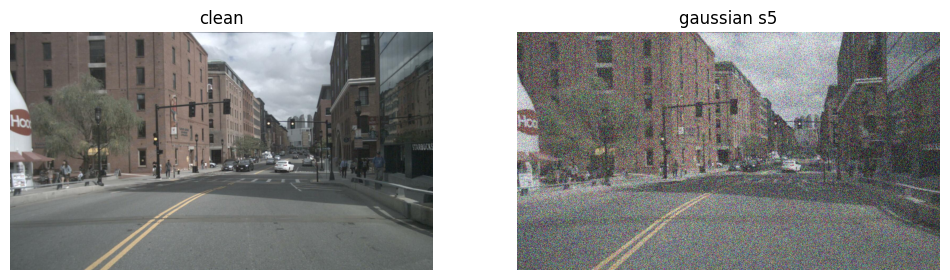

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

clean_root = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes")
gauss_root = Path("/content/nuscenes_gaussian_s5")

clean_img = sorted((clean_root / "samples" / "CAM_FRONT").glob("*.jpg"))[0]
gauss_img = gauss_root / "samples" / "CAM_FRONT" / clean_img.name

print("clean:", clean_img)
print("gauss:", gauss_img, gauss_img.exists())

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(Image.open(clean_img))
plt.title("clean")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(Image.open(gauss_img))
plt.title("gaussian s5")
plt.axis("off")

plt.show()

In [ ]:
from pathlib import Path
import hashlib

logs = {
    "clean": Path("/content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_clean/eval.log"),
    "gaussian_s5": Path("/content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_gaussian_s5/eval.log"),
}

for name, p in logs.items():
    data = p.read_bytes()
    print(name)
    print("path:", p)
    print("size:", len(data))
    print("md5:", hashlib.md5(data).hexdigest())
    print("last metric lines:")
    for line in p.read_text().splitlines():
        if line.startswith("mAP:") or line.startswith("NDS:"):
            print(" ", line)
    print()

clean
path: /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_clean/eval.log
size: 32912
md5: fc1ef72ea6d09a781a285c919f62c5ca
last metric lines:
  mAP: 0.3349
  NDS: 0.3828

gaussian_s5
path: /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_gaussian_s5/eval.log
size: 32916
md5: 53e025fcb4fe2caafa2de32526f93ebd
last metric lines:
  mAP: 0.3349
  NDS: 0.3828



In [ ]:
from pathlib import Path
import re

logs = {
    "camera_only_clean": Path("/content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_clean/eval.log"),
    "camera_only_gaussian_s5": Path("/content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_gaussian_s5/eval.log"),
}

for name, p in logs.items():
    text = p.read_text()
    map_line = re.findall(r"^mAP:\s*([0-9.]+)", text, flags=re.M)
    nds_line = re.findall(r"^NDS:\s*([0-9.]+)", text, flags=re.M)

    print(name)
    print("mAP line:", map_line[-1] if map_line else None)
    print("NDS line:", nds_line[-1] if nds_line else None)

    dict_lines = [line.strip() for line in text.splitlines() if line.strip().startswith("{'object/")]
    if dict_lines:
        metrics = eval(dict_lines[-1], {"__builtins__": {}}, {"nan": float("nan")})
        print("object/map:", metrics["object/map"])
        print("object/nds:", metrics["object/nds"])
    print()

camera_only_clean
mAP line: 0.3349
NDS line: 0.3828
object/map: 0.3349103919678925
object/nds: 0.3828480879569992

camera_only_gaussian_s5
mAP line: 0.3349
NDS line: 0.3828
object/map: 0.3349102587596555
object/nds: 0.38284722830935153



## camera blackout s5
* evaluation failed after inference
* reason: Invalid box type None
* interpretation: no valid predictions / severe failure under camera blackout

In [ ]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm
import shutil
import os

SRC = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes")
DST = Path("/content/nuscenes_camera_blackout_s5")

camera_dirs = [
    "CAM_FRONT",
    "CAM_FRONT_RIGHT",
    "CAM_FRONT_LEFT",
    "CAM_BACK",
    "CAM_BACK_RIGHT",
    "CAM_BACK_LEFT",
]

if DST.exists():
    shutil.rmtree(DST)

DST.mkdir(parents=True, exist_ok=True)

shutil.copytree(SRC / "v1.0-mini", DST / "v1.0-mini")
shutil.copytree(SRC / "maps", DST / "maps")

for p in SRC.glob("*.pkl"):
    shutil.copy2(p, DST / p.name)

if (SRC / "LICENSE").exists():
    shutil.copy2(SRC / "LICENSE", DST / "LICENSE")

(DST / "samples").mkdir()

for cam in camera_dirs:
    shutil.copytree(SRC / "samples" / cam, DST / "samples" / cam)

os.symlink(SRC / "samples" / "LIDAR_TOP", DST / "samples" / "LIDAR_TOP")
os.symlink(SRC / "sweeps", DST / "sweeps")

image_paths = []
for cam in camera_dirs:
    image_paths.extend((DST / "samples" / cam).glob("*.jpg"))

print("camera sample images:", len(image_paths))

for p in tqdm(image_paths):
    img = Image.open(p).convert("RGB")
    black = Image.new("RGB", img.size, (0, 0, 0))
    black.save(p, quality=95)

print("Camera blackout done:", DST)

KeyboardInterrupt: 

In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_camera_blackout_s5 data/nuscenes

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_blackout_s5

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml \
  pretrained/camera-only-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_blackout_s5/eval.log

/content/bevfusion_mit
Config (path: configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 20, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 20}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': 15, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-51.2, -51.2, -5.0, 51.2, 51.2, 3.0], 'voxel_size': [0.1, 0.1, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.95, 1.05], 'rotate': [-0.3925, 0.3925], 'translate'

## camera_dark_s5

In [ ]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm
import shutil
import os
import numpy as np

SRC = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes")
DST = Path("/content/nuscenes_camera_dark_s5")

camera_dirs = [
    "CAM_FRONT",
    "CAM_FRONT_RIGHT",
    "CAM_FRONT_LEFT",
    "CAM_BACK",
    "CAM_BACK_RIGHT",
    "CAM_BACK_LEFT",
]

if DST.exists():
    shutil.rmtree(DST)

DST.mkdir(parents=True, exist_ok=True)

shutil.copytree(SRC / "v1.0-mini", DST / "v1.0-mini")
shutil.copytree(SRC / "maps", DST / "maps")

for p in SRC.glob("*.pkl"):
    shutil.copy2(p, DST / p.name)

if (SRC / "LICENSE").exists():
    shutil.copy2(SRC / "LICENSE", DST / "LICENSE")

(DST / "samples").mkdir()

for cam in camera_dirs:
    shutil.copytree(SRC / "samples" / cam, DST / "samples" / cam)

# non-camera samples symlink back to original
for d in (SRC / "samples").iterdir():
    if d.is_dir() and d.name not in camera_dirs:
        os.symlink(d, DST / "samples" / d.name)

os.symlink(SRC / "sweeps", DST / "sweeps")

# darken camera images
image_paths = []
for cam in camera_dirs:
    image_paths.extend((DST / "samples" / cam).glob("*.jpg"))

print("camera sample images:", len(image_paths))

for p in tqdm(image_paths):
    img = Image.open(p).convert("RGB")
    arr = np.asarray(img).astype(np.float32)
    dark = np.clip(arr * 0.1, 0, 255).astype(np.uint8)
    Image.fromarray(dark).save(p, quality=95)

print("Camera dark s5 done:", DST)

KeyboardInterrupt: 

In [ ]:
script = r'''
import mmcv
from pathlib import Path

OLD_ROOT = "/content/drive/MyDrive/BEVFusion_Project/data/nuscenes"
NEW_ROOT = "/content/nuscenes_camera_dark_s5"

def replace_paths(obj):
    if isinstance(obj, dict):
        return {k: replace_paths(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [replace_paths(v) for v in obj]
    if isinstance(obj, tuple):
        return tuple(replace_paths(v) for v in obj)
    if isinstance(obj, str):
        return obj.replace(OLD_ROOT, NEW_ROOT)
    return obj

for name in [
    "nuscenes_infos_train.pkl",
    "nuscenes_infos_val.pkl",
    "nuscenes_infos_train_radar.pkl",
    "nuscenes_infos_val_radar.pkl",
]:
    p = Path(NEW_ROOT) / name
    if p.exists():
        data = mmcv.load(str(p))
        data = replace_paths(data)
        mmcv.dump(data, str(p))
        print("patched:", p)
'''

with open("/content/patch_dark_pkl_paths.py", "w") as f:
    f.write(script)

! /content/bin/micromamba run -p /content/bevfusion_env python /content/patch_dark_pkl_paths.py

patched: /content/nuscenes_camera_dark_s5/nuscenes_infos_train.pkl
patched: /content/nuscenes_camera_dark_s5/nuscenes_infos_val.pkl
patched: /content/nuscenes_camera_dark_s5/nuscenes_infos_train_radar.pkl
patched: /content/nuscenes_camera_dark_s5/nuscenes_infos_val_radar.pkl


In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_camera_dark_s5 data/nuscenes

!readlink -f data/nuscenes
!find data/nuscenes/samples -path "*CAM_*" -type f | wc -l

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_dark_s5

!rm -f /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_dark_s5/eval.log

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml \
  pretrained/camera-only-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_dark_s5/eval.log

/content/bevfusion_mit
/content/nuscenes_camera_dark_s5
2424
Config (path: configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 20, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 20}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': 15, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-51.2, -51.2, -5.0, 51.2, 51.2, 3.0], 'voxel_size': [0.1, 0.1, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.95, 1.05], 'r

##  camera+lidar dark s5

In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_camera_dark_s5 data/nuscenes

!readlink -f data/nuscenes
!find data/nuscenes/samples -path "*CAM_*" -type f | wc -l

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_lidar_dark_s5

!rm -f /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_lidar_dark_s5/eval.log

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml \
  pretrained/bevfusion-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_lidar_dark_s5/eval.log

/content/bevfusion_mit
/content/nuscenes_camera_dark_s5
2424
Config (path: configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 6, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 6}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': -1, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-54.0, -54.0, -5.0, 54.0, 54.0, 3.0], 'voxel_size': [0.075, 0.075, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.9, 

## 建立 /content/nuscenes_camera_dark_s3

In [ ]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm
import shutil
import os
import numpy as np

SRC = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes")
DST = Path("/content/nuscenes_camera_dark_s3")

camera_dirs = [
    "CAM_FRONT",
    "CAM_FRONT_RIGHT",
    "CAM_FRONT_LEFT",
    "CAM_BACK",
    "CAM_BACK_RIGHT",
    "CAM_BACK_LEFT",
]

if DST.exists():
    shutil.rmtree(DST)

DST.mkdir(parents=True, exist_ok=True)

shutil.copytree(SRC / "v1.0-mini", DST / "v1.0-mini")
shutil.copytree(SRC / "maps", DST / "maps")

for p in SRC.glob("*.pkl"):
    shutil.copy2(p, DST / p.name)

if (SRC / "LICENSE").exists():
    shutil.copy2(SRC / "LICENSE", DST / "LICENSE")

(DST / "samples").mkdir()

# camera samples 複製，因為要改圖
for cam in camera_dirs:
    shutil.copytree(SRC / "samples" / cam, DST / "samples" / cam)

# non-camera samples symlink 回原始資料
for d in (SRC / "samples").iterdir():
    if d.is_dir() and d.name not in camera_dirs:
        os.symlink(d, DST / "samples" / d.name)

# sweeps 不改，直接 symlink
os.symlink(SRC / "sweeps", DST / "sweeps")

# dark s3: brightness 30%
image_paths = []
for cam in camera_dirs:
    image_paths.extend((DST / "samples" / cam).glob("*.jpg"))

print("camera sample images:", len(image_paths))

for p in tqdm(image_paths):
    img = Image.open(p).convert("RGB")
    arr = np.asarray(img).astype(np.float32)
    dark = np.clip(arr * 0.3, 0, 255).astype(np.uint8)
    Image.fromarray(dark).save(p, quality=95)

print("Camera dark s3 done:", DST)

camera sample images: 2424


100%|██████████| 2424/2424 [01:30<00:00, 26.79it/s]

Camera dark s3 done: /content/nuscenes_camera_dark_s3


## patch pkl 路徑

In [ ]:
script = r'''
import mmcv
from pathlib import Path

OLD_ROOT = "/content/drive/MyDrive/BEVFusion_Project/data/nuscenes"
NEW_ROOT = "/content/nuscenes_camera_dark_s3"

def replace_paths(obj):
    if isinstance(obj, dict):
        return {k: replace_paths(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [replace_paths(v) for v in obj]
    if isinstance(obj, tuple):
        return tuple(replace_paths(v) for v in obj)
    if isinstance(obj, str):
        return obj.replace(OLD_ROOT, NEW_ROOT)
    return obj

for name in [
    "nuscenes_infos_train.pkl",
    "nuscenes_infos_val.pkl",
    "nuscenes_infos_train_radar.pkl",
    "nuscenes_infos_val_radar.pkl",
]:
    p = Path(NEW_ROOT) / name
    if p.exists():
        data = mmcv.load(str(p))
        data = replace_paths(data)
        mmcv.dump(data, str(p))
        print("patched:", p)
'''

with open("/content/patch_dark_s3_pkl_paths.py", "w") as f:
    f.write(script)

! /content/bin/micromamba run -p /content/bevfusion_env python /content/patch_dark_s3_pkl_paths.py

patched: /content/nuscenes_camera_dark_s3/nuscenes_infos_train.pkl
patched: /content/nuscenes_camera_dark_s3/nuscenes_infos_val.pkl
patched: /content/nuscenes_camera_dark_s3/nuscenes_infos_train_radar.pkl
patched: /content/nuscenes_camera_dark_s3/nuscenes_infos_val_radar.pkl


In [ ]:
%cd /content/bevfusion_mit

from pathlib import Path

patches = [
    (
        Path("mmdet3d/ops/__init__.py"),
        "from .feature_decorator import feature_decorator",
        "# from .feature_decorator import feature_decorator  # disabled: optional radar op not compiled",
    ),
    (
        Path("mmdet3d/models/backbones/__init__.py"),
        "from .radar_encoder import *",
        "# from .radar_encoder import *  # disabled: optional radar op not compiled",
    ),
]

for path, old, new in patches:
    text = path.read_text()
    if old in text:
        text = text.replace(old, new)
        path.write_text(text)
        print("patched:", path)
    elif new in text:
        print("already patched:", path)
    else:
        print("target not found:", path)

/content/bevfusion_mit
patched: mmdet3d/ops/__init__.py
patched: mmdet3d/models/backbones/__init__.py


In [ ]:
%cd /content/bevfusion_mit

from pathlib import Path

p = Path("mmdet3d/models/vtransforms/depth_lss.py")
s = p.read_text()

if "add_depth_features=False" not in s:
    old = "dbound=dbound,\n        )"
    new = "dbound=dbound,\n            add_depth_features=False,\n        )"
    s = s.replace(old, new, 1)
    p.write_text(s)
    print("patched depth_lss.py")
else:
    print("depth_lss.py already patched")

/content/bevfusion_mit
depth_lss.py already patched


## camera-only dark s3

In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_camera_dark_s3 data/nuscenes

!readlink -f data/nuscenes
!find data/nuscenes/samples -path "*CAM_*" -type f | wc -l

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_dark_s3
!rm -f /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_dark_s3/eval.log

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml \
  pretrained/camera-only-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_dark_s3/eval.log

/content/bevfusion_mit
/content/nuscenes_camera_dark_s3
2424
Config (path: configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 20, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 20}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': 15, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-51.2, -51.2, -5.0, 51.2, 51.2, 3.0], 'voxel_size': [0.1, 0.1, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.95, 1.05], 'r

## camera+lidar dark s3

In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_camera_dark_s3 data/nuscenes

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_lidar_dark_s3
!rm -f /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_lidar_dark_s3/eval.log

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml \
  pretrained/bevfusion-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_lidar_dark_s3/eval.log

/content/bevfusion_mit
Config (path: configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 6, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 6}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': -1, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-54.0, -54.0, -5.0, 54.0, 54.0, 3.0], 'voxel_size': [0.075, 0.075, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.9, 1.1], 'rotate': [-0.78539816, 0.785398

## camera_dark_s1

In [ ]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm
import shutil
import os
import numpy as np

SRC = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes")
DST = Path("/content/nuscenes_camera_dark_s1")

camera_dirs = [
    "CAM_FRONT",
    "CAM_FRONT_RIGHT",
    "CAM_FRONT_LEFT",
    "CAM_BACK",
    "CAM_BACK_RIGHT",
    "CAM_BACK_LEFT",
]

if DST.exists():
    shutil.rmtree(DST)

DST.mkdir(parents=True, exist_ok=True)

shutil.copytree(SRC / "v1.0-mini", DST / "v1.0-mini")
shutil.copytree(SRC / "maps", DST / "maps")

for p in SRC.glob("*.pkl"):
    shutil.copy2(p, DST / p.name)

if (SRC / "LICENSE").exists():
    shutil.copy2(SRC / "LICENSE", DST / "LICENSE")

(DST / "samples").mkdir()

# camera samples: copy then corrupt
for cam in camera_dirs:
    shutil.copytree(SRC / "samples" / cam, DST / "samples" / cam)

# non-camera samples: symlink back to original
for d in (SRC / "samples").iterdir():
    if d.is_dir() and d.name not in camera_dirs:
        os.symlink(d, DST / "samples" / d.name)

# sweeps: symlink original
os.symlink(SRC / "sweeps", DST / "sweeps")

# dark s1: 70% brightness
image_paths = []
for cam in camera_dirs:
    image_paths.extend((DST / "samples" / cam).glob("*.jpg"))

print("camera sample images:", len(image_paths))

for p in tqdm(image_paths):
    img = Image.open(p).convert("RGB")
    arr = np.asarray(img).astype(np.float32)
    dark = np.clip(arr * 0.7, 0, 255).astype(np.uint8)
    Image.fromarray(dark).save(p, quality=95)

print("Camera dark s1 done:", DST)

camera sample images: 2424


100%|██████████| 2424/2424 [01:32<00:00, 26.25it/s]

Camera dark s1 done: /content/nuscenes_camera_dark_s1


## Patch pkl 路徑

In [ ]:
script = r'''
import mmcv
from pathlib import Path

OLD_ROOT = "/content/drive/MyDrive/BEVFusion_Project/data/nuscenes"
NEW_ROOT = "/content/nuscenes_camera_dark_s1"

def replace_paths(obj):
    if isinstance(obj, dict):
        return {k: replace_paths(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [replace_paths(v) for v in obj]
    if isinstance(obj, tuple):
        return tuple(replace_paths(v) for v in obj)
    if isinstance(obj, str):
        return obj.replace(OLD_ROOT, NEW_ROOT)
    return obj

for name in [
    "nuscenes_infos_train.pkl",
    "nuscenes_infos_val.pkl",
    "nuscenes_infos_train_radar.pkl",
    "nuscenes_infos_val_radar.pkl",
]:
    p = Path(NEW_ROOT) / name
    if p.exists():
        data = mmcv.load(str(p))
        data = replace_paths(data)
        mmcv.dump(data, str(p))
        print("patched:", p)
'''

with open("/content/patch_dark_s1_pkl_paths.py", "w") as f:
    f.write(script)

! /content/bin/micromamba run -p /content/bevfusion_env python /content/patch_dark_s1_pkl_paths.py

patched: /content/nuscenes_camera_dark_s1/nuscenes_infos_train.pkl
patched: /content/nuscenes_camera_dark_s1/nuscenes_infos_val.pkl
patched: /content/nuscenes_camera_dark_s1/nuscenes_infos_train_radar.pkl
patched: /content/nuscenes_camera_dark_s1/nuscenes_infos_val_radar.pkl


## camera-only dark s1

In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_camera_dark_s1 data/nuscenes

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_dark_s1
!rm -f /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_dark_s1/eval.log

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml \
  pretrained/camera-only-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_only_dark_s1/eval.log

/content/bevfusion_mit
Config (path: configs/nuscenes/det/centerhead/lssfpn/camera/256x704/swint/default.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 20, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 20}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': 15, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-51.2, -51.2, -5.0, 51.2, 51.2, 3.0], 'voxel_size': [0.1, 0.1, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.95, 1.05], 'rotate': [-0.3925, 0.3925], 'translate'

## camera+lidar dark s1

In [ ]:
%cd /content/bevfusion_mit

!rm -rf data/nuscenes
!mkdir -p data
!ln -s /content/nuscenes_camera_dark_s1 data/nuscenes

!mkdir -p /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_lidar_dark_s1
!rm -f /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_lidar_dark_s1/eval.log

!RDMAV_FORK_SAFE=1 \
 OMPI_MCA_mtl=^ofi \
 OMPI_MCA_pml=ob1 \
 OMPI_MCA_btl=self,tcp \
 /content/bin/micromamba run -p /content/bevfusion_env torchpack dist-run -np 1 \
  python tools/test.py \
  configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml \
  pretrained/bevfusion-det.pth \
  --eval bbox \
  --cfg-options data.workers_per_gpu=0 data.test.samples_per_gpu=1 \
  2>&1 | tee /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_lidar_dark_s1/eval.log

/content/bevfusion_mit
Config (path: configs/nuscenes/det/transfusion/secfpn/camera+lidar/swint_v0p075/convfuser.yaml): {'seed': 0, 'deterministic': False, 'checkpoint_config': {'interval': 1, 'max_keep_ckpts': 1}, 'log_config': {'interval': 50, 'hooks': [{'type': 'TextLoggerHook'}, {'type': 'TensorboardLoggerHook'}]}, 'load_from': None, 'resume_from': None, 'cudnn_benchmark': False, 'fp16': {'loss_scale': {'growth_interval': 2000}}, 'max_epochs': 6, 'runner': {'type': 'CustomEpochBasedRunner', 'max_epochs': 6}, 'dataset_type': 'NuScenesDataset', 'dataset_root': 'data/nuscenes/', 'gt_paste_stop_epoch': -1, 'reduce_beams': 32, 'load_dim': 5, 'use_dim': 5, 'load_augmented': None, 'point_cloud_range': [-54.0, -54.0, -5.0, 54.0, 54.0, 3.0], 'voxel_size': [0.075, 0.075, 0.2], 'image_size': [256, 704], 'augment2d': {'resize': [[0.38, 0.55], [0.48, 0.48]], 'rotate': [-5.4, 5.4], 'gridmask': {'prob': 0.0, 'fixed_prob': True}}, 'augment3d': {'scale': [0.9, 1.1], 'rotate': [-0.78539816, 0.785398

In [ ]:
from pathlib import Path
import math
import pandas as pd

# ====== 每次實驗改這裡 ======
model = "camera_lidar"
experiment = "camera_lidar_dark_s1"
corruption = "dark"
severity = 1
eval_log = Path("/content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/camera_lidar_dark_s1/eval.log")
# ============================

out_dir = Path("/content/drive/MyDrive/BEVFusion_Project/outputs/model_compare")
out_dir.mkdir(parents=True, exist_ok=True)

summary_csv = out_dir / "model_compare_summary.csv"
detail_csv = out_dir / "model_compare_detail_metrics.csv"

text = eval_log.read_text()

dict_lines = []
for line in text.splitlines():
    line = line.strip()
    if line.startswith("{'object/") and line.endswith("}"):
        dict_lines.append(line)

if not dict_lines:
    raise RuntimeError("找不到 metrics dict")

metrics = eval(dict_lines[-1], {"__builtins__": {}}, {"nan": float("nan")})

summary_row = {
    "model": model,
    "experiment": experiment,
    "corruption": corruption,
    "severity": severity,
    "mAP": metrics["object/map"],
    "NDS": metrics["object/nds"],
    "mATE": metrics["object/mATE"],
    "mASE": metrics["object/mASE"],
    "mAOE": metrics["object/mAOE"],
    "mAVE": metrics["object/mAVE"],
    "mAAE": metrics["object/mAAE"],
}

summary_fields = [
    "model", "experiment", "corruption", "severity",
    "mAP", "NDS", "mATE", "mASE", "mAOE", "mAVE", "mAAE",
]

if summary_csv.exists():
    df = pd.read_csv(summary_csv)
    df = df[df["experiment"] != experiment]
else:
    df = pd.DataFrame(columns=summary_fields)

df = pd.concat([df, pd.DataFrame([summary_row])], ignore_index=True)
df = df[summary_fields]
df.to_csv(summary_csv, index=False)

def clean_value(v):
    if isinstance(v, float) and math.isnan(v):
        return "nan"
    return v

detail_rows = []
for k, v in metrics.items():
    detail_rows.append({
        "model": model,
        "experiment": experiment,
        "corruption": corruption,
        "severity": severity,
        "metric": k,
        "value": clean_value(v),
    })

detail_fields = ["model", "experiment", "corruption", "severity", "metric", "value"]

if detail_csv.exists():
    detail_df = pd.read_csv(detail_csv)
    detail_df = detail_df[detail_df["experiment"] != experiment]
else:
    detail_df = pd.DataFrame(columns=detail_fields)

detail_df = pd.concat([detail_df, pd.DataFrame(detail_rows)], ignore_index=True)
detail_df = detail_df[detail_fields]
detail_df.to_csv(detail_csv, index=False)

print("Saved:", summary_csv)
print("Saved:", detail_csv)

display(df)

Saved: /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/model_compare_summary.csv
Saved: /content/drive/MyDrive/BEVFusion_Project/outputs/model_compare/model_compare_detail_metrics.csv


,model,experiment,corruption,severity,mAP,NDS,mATE,mASE,mAOE,mAVE,mAAE
0,camera_only,camera_only_clean,none,0,0.334910,0.382848,0.6987,0.4597,0.7092,0.6157,0.3627
1,camera_only,camera_only_dark_s5,dark,5,0.000000,0.000000,1.0000,1.0000,1.0000,1.0000,1.0000
2,camera_lidar,camera_lidar_dark_s5,dark,5,0.516704,0.554665,0.4056,0.4374,0.4697,0.4127,0.3114
3,camera_only,camera_only_dark_s3,dark,3,0.137325,0.206400,0.8548,0.4729,1.0116,0.8803,0.4145
4,camera_lidar,camera_lidar_dark_s3,dark,3,0.550126,0.568952,0.4047,0.4434,0.4685,0.4258,0.3187
5,camera_only,camera_only_gaussian_s5,gaussian_noise,5,0.024875,0.038513,0.9699,0.8708,0.9991,0.9913,0.9082
6,camera_lidar,camera_lidar_gaussian_s5,gaussian_noise,5,0.527589,0.558272,0.4049,0.4421,0.4688,0.4150,0.3244
7,camera_only,camera_only_dark_s1,dark,1,0.324908,0.373184,0.7344,0.4655,0.7303,0.6011,0.3615
8,camera_lidar,camera_lidar_dark_s1,dark,1,0.572507,0.578435,0.4055,0.4461,0.4780,0.4261,0.3225


FileNotFoundError: [Errno 2] No such file or directory: '/content/nuscenes_gaussian_s5/samples/CAM_FRONT/n008-2018-08-01-15-16-36-0400__CAM_FRONT__1533151603512404.jpg'

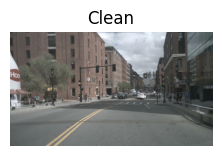

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

clean_root = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes")
gauss_root = Path("/content/nuscenes_gaussian_s5")
dark_s3_root = Path("/content/nuscenes_camera_dark_s3")
dark_s5_root = Path("/content/nuscenes_camera_dark_s5")

# 選同一張 CAM_FRONT 圖
clean_img = sorted((clean_root / "samples" / "CAM_FRONT").glob("*.jpg"))[0]
name = clean_img.name

paths = [
    ("Clean", clean_img),
    ("Gaussian noise s5", gauss_root / "samples" / "CAM_FRONT" / name),
    ("Dark s3", dark_s3_root / "samples" / "CAM_FRONT" / name),
    ("Dark s5", dark_s5_root / "samples" / "CAM_FRONT" / name),
]

plt.figure(figsize=(12, 5))

for i, (title, path) in enumerate(paths, 1):
    img = Image.open(path).convert("RGB")
    plt.subplot(1, 4, i)
    plt.imshow(img)
    plt.title(title, fontsize=12)
    plt.axis("off")

plt.tight_layout()

out = "/content/drive/MyDrive/BEVFusion_Project/outputs/corruption_visualization.png"
plt.savefig(out, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", out)

saved: /content/drive/MyDrive/BEVFusion_Project/visualizations/clean_CAM_FRONT.jpg
saved: /content/drive/MyDrive/BEVFusion_Project/visualizations/gaussian_s5_CAM_FRONT.jpg
saved: /content/drive/MyDrive/BEVFusion_Project/visualizations/dark_s3_CAM_FRONT.jpg
saved: /content/drive/MyDrive/BEVFusion_Project/visualizations/dark_s5_CAM_FRONT.jpg


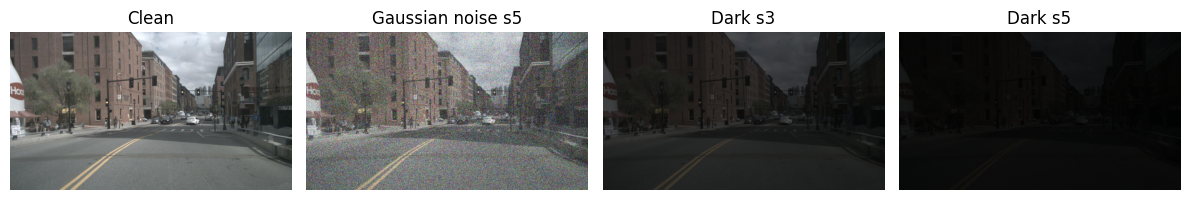

Saved visualization: /content/drive/MyDrive/BEVFusion_Project/visualizations/corruption_visualization.png


In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import shutil

VIS_DIR = Path("/content/drive/MyDrive/BEVFusion_Project/visualizations")
VIS_DIR.mkdir(parents=True, exist_ok=True)

clean_root = Path("/content/drive/MyDrive/BEVFusion_Project/data/nuscenes")
clean_img = sorted((clean_root / "samples" / "CAM_FRONT").glob("*.jpg"))[0]

img = Image.open(clean_img).convert("RGB")
arr = np.asarray(img).astype(np.float32)

# Clean
clean = np.clip(arr, 0, 255).astype(np.uint8)

# Gaussian noise s5
rng = np.random.default_rng(0)
sigma = 0.38 * 255.0
noise = rng.normal(0.0, sigma, arr.shape)
gaussian_s5 = np.clip(arr + noise, 0, 255).astype(np.uint8)

# Dark s3 / s5
dark_s3 = np.clip(arr * 0.3, 0, 255).astype(np.uint8)
dark_s5 = np.clip(arr * 0.1, 0, 255).astype(np.uint8)

items = [
    ("clean_CAM_FRONT.jpg", clean),
    ("gaussian_s5_CAM_FRONT.jpg", gaussian_s5),
    ("dark_s3_CAM_FRONT.jpg", dark_s3),
    ("dark_s5_CAM_FRONT.jpg", dark_s5),
]

for name, data in items:
    out = VIS_DIR / name
    Image.fromarray(data).save(out, quality=95)
    print("saved:", out)

# Make 4-panel visualization
paths = [
    ("Clean", VIS_DIR / "clean_CAM_FRONT.jpg"),
    ("Gaussian noise s5", VIS_DIR / "gaussian_s5_CAM_FRONT.jpg"),
    ("Dark s3", VIS_DIR / "dark_s3_CAM_FRONT.jpg"),
    ("Dark s5", VIS_DIR / "dark_s5_CAM_FRONT.jpg"),
]

plt.figure(figsize=(12, 5))

for i, (title, path) in enumerate(paths, 1):
    im = Image.open(path).convert("RGB")
    plt.subplot(1, 4, i)
    plt.imshow(im)
    plt.title(title, fontsize=12)
    plt.axis("off")

plt.tight_layout()

out = VIS_DIR / "corruption_visualization.png"
plt.savefig(out, dpi=250, bbox_inches="tight")
plt.show()

print("Saved visualization:", out)

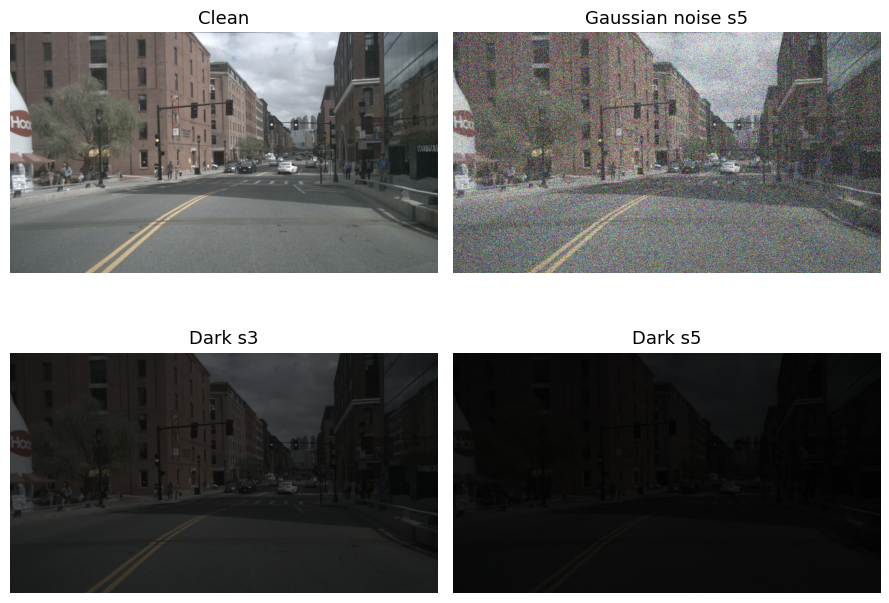

Saved visualization: /content/drive/MyDrive/BEVFusion_Project/visualizations/corruption_visualization_2x2.png


In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

VIS_DIR = Path("/content/drive/MyDrive/BEVFusion_Project/visualizations")

paths = [
    ("Clean", VIS_DIR / "clean_CAM_FRONT.jpg"),
    ("Gaussian noise s5", VIS_DIR / "gaussian_s5_CAM_FRONT.jpg"),
    ("Dark s3", VIS_DIR / "dark_s3_CAM_FRONT.jpg"),
    ("Dark s5", VIS_DIR / "dark_s5_CAM_FRONT.jpg"),
]

plt.figure(figsize=(9, 7))

for i, (title, path) in enumerate(paths, 1):
    im = Image.open(path).convert("RGB")
    plt.subplot(2, 2, i)
    plt.imshow(im)
    plt.title(title, fontsize=13)
    plt.axis("off")

plt.tight_layout()

out = VIS_DIR / "corruption_visualization_2x2.png"
plt.savefig(out, dpi=250, bbox_inches="tight")
plt.show()

print("Saved visualization:", out)